# Customer Satisfaction Prediction & Interactive Dashboard

**Tools:** Python, Pandas, Matplotlib, Seaborn, Plotly, Scikit-learn

## Objective
Explore customer-service satisfaction, identify patterns associated with low satisfaction, and evaluate a Decision Tree classifier.

**Target definition:** CSAT 1–3 = Low satisfaction; CSAT 4–5 = High satisfaction.

> Run cells in order. Keep `Customer_support_data.csv` in the same folder as this notebook, or update the path in Cell 3. The dashboard uses Plotly for interactive charts. The optional filter controls use `ipywidgets`.


## Cell 1 — Install required libraries
Run this cell once if the packages are not installed.

In [1]:
%pip install pandas numpy matplotlib seaborn plotly scikit-learn ipywidgets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cell 2 — Import libraries
Import data handling, visualization, and machine-learning tools.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## Cell 3 — Load the dataset
Change `file_path` if your CSV is stored somewhere else.

In [4]:
file_path = "Customer_support_data.csv"
df = pd.read_csv(file_path)

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset loaded: 85,907 rows × 20 columns


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


## Cell 4 — Inspect the dataset
Review column names, types, missing values, and duplicates before cleaning.

In [5]:
print("Columns:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nDuplicate rows:", df.duplicated().sum())

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).query("`Missing Count` > 0").sort_values("Missing Percent", ascending=False)

display(missing_summary)


Columns:
['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at    

,Missing Count,Missing Percent
connected_handling_time,85665,99.72
Customer_City,68828,80.12
Product_category,68711,79.98
Item_price,68701,79.97
order_date_time,68693,79.96
Customer Remarks,57165,66.54
Order_id,18232,21.22


## Cell 5 — Prepare the target and waiting-time feature
We derive waiting time from the issue-reported and issue-responded timestamps. Negative durations are invalid. Missing durations are filled with the median for descriptive charts; the model pipeline separately imputes missing inputs.

In [6]:
required_columns = [
    "CSAT Score", "Issue_reported at", "issue_responded",
    "category", "Sub-category", "Product_category", "Agent Shift", "channel_name"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"These expected columns are missing: {missing_columns}")

df["CSAT Score"] = pd.to_numeric(df["CSAT Score"], errors="coerce")

for col in ["Issue_reported at", "issue_responded"]:
    df[col] = pd.to_datetime(df[col], errors="coerce", dayfirst=True)

df["waiting_time_hours"] = (
    df["issue_responded"] - df["Issue_reported at"]
).dt.total_seconds() / 3600

df.loc[df["waiting_time_hours"] < 0, "waiting_time_hours"] = np.nan

# Keep records with a valid target score between 1 and 5
df = df[df["CSAT Score"].between(1, 5)].copy()

if df["waiting_time_hours"].notna().any():
    median_wait = df["waiting_time_hours"].median()
    df["waiting_time_hours"] = df["waiting_time_hours"].fillna(median_wait)
else:
    median_wait = 0.0
    df["waiting_time_hours"] = 0.0

df["Satisfaction"] = np.where(df["CSAT Score"] >= 4, "High", "Low")

print("Rows with valid CSAT:", f"{len(df):,}")
print("Median waiting time used for missing values:", round(median_wait, 2), "hours")
display(df[["CSAT Score", "Satisfaction", "Issue_reported at", "issue_responded", "waiting_time_hours"]].head())


Rows with valid CSAT: 85,907
Median waiting time used for missing values: 0.1 hours


,CSAT Score,Satisfaction,Issue_reported at,issue_responded,waiting_time_hours
0,5,High,2023-08-01 11:13:00,2023-08-01 11:47:00,0.566667
1,5,High,2023-08-01 12:52:00,2023-08-01 12:54:00,0.033333
2,5,High,2023-08-01 20:16:00,2023-08-01 20:38:00,0.366667
3,5,High,2023-08-01 20:56:00,2023-08-01 21:16:00,0.333333
4,5,High,2023-08-01 10:30:00,2023-08-01 10:32:00,0.033333


## Cell 6 — Create dashboard KPI cards
These four cards summarize the filtered dataset view (initially all valid records).

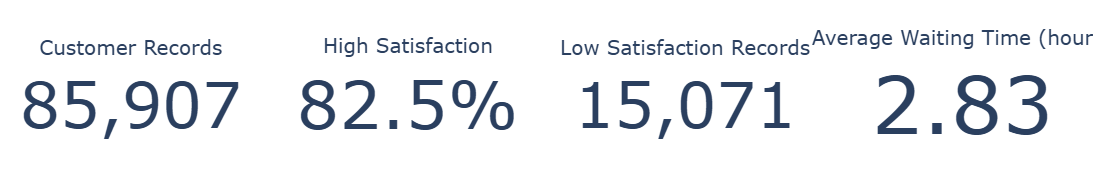

Average CSAT score: 4.24 / 5


In [7]:
total_records = len(df)
high_rate = (df["Satisfaction"] == "High").mean() * 100
low_records = (df["Satisfaction"] == "Low").sum()
average_wait = df["waiting_time_hours"].mean()
average_csat = df["CSAT Score"].mean()

kpi_specs = [
    ("Customer Records", total_records, ",.0f"),
    ("High Satisfaction", high_rate, ".1f"),
    ("Low Satisfaction Records", low_records, ",.0f"),
    ("Average Waiting Time (hours)", average_wait, ".2f"),
]

fig = go.Figure()
for i, (label, value, fmt) in enumerate(kpi_specs):
    suffix = "%" if label == "High Satisfaction" else ""
    fig.add_trace(go.Indicator(
        mode="number",
        value=float(value),
        number={"valueformat": fmt, "suffix": suffix},
        title={"text": label},
        domain={"row": 0, "column": i}
    ))

fig.update_layout(
    grid={"rows": 1, "columns": 4, "pattern": "independent"},
    height=180,
    margin=dict(l=20, r=20, t=35, b=10)
)
fig.show()
print(f"Average CSAT score: {average_csat:.2f} / 5")


## Cell 7 — CSAT score distribution
This chart shows the number of records for each original CSAT score.

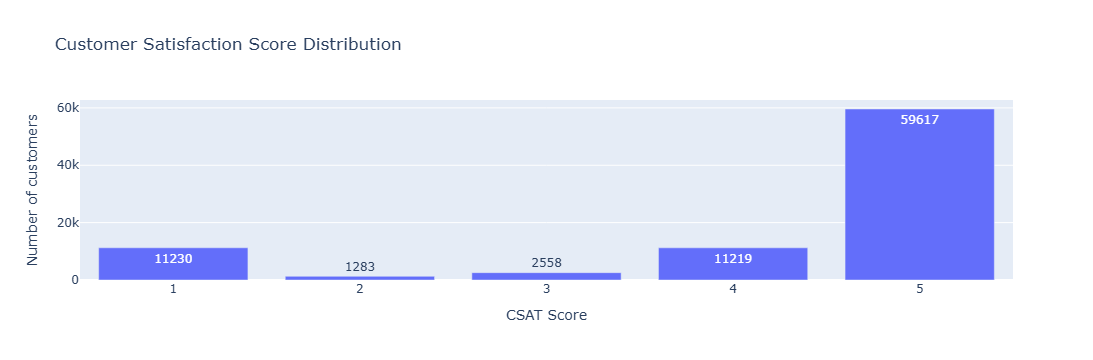

In [8]:
csat_counts = df["CSAT Score"].value_counts().sort_index().reset_index()
csat_counts.columns = ["CSAT Score", "Customers"]

fig = px.bar(
    csat_counts, x="CSAT Score", y="Customers",
    title="Customer Satisfaction Score Distribution",
    text="Customers"
)
fig.update_layout(xaxis_title="CSAT Score", yaxis_title="Number of customers")
fig.show()


## Cell 8 — Waiting time vs satisfaction
Compare response-time distributions for high- and low-satisfaction records. Extreme durations can stretch a chart, so inspect medians as well as means.

,Count,Mean,Median
Satisfaction,,,
High,70836,2.22,0.08
Low,15071,5.71,0.28


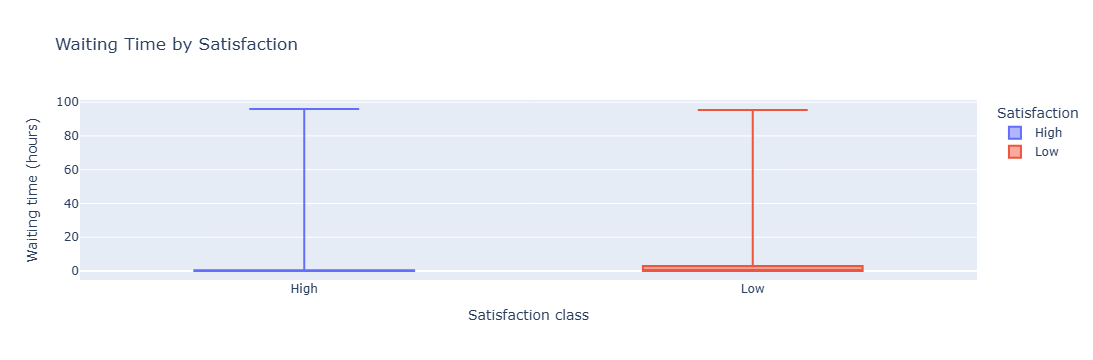

In [9]:
wait_summary = df.groupby("Satisfaction")["waiting_time_hours"].agg(
    Count="count", Mean="mean", Median="median"
).round(2)
display(wait_summary)

fig = px.box(
    df, x="Satisfaction", y="waiting_time_hours", color="Satisfaction",
    points=False, title="Waiting Time by Satisfaction"
)
fig.update_layout(xaxis_title="Satisfaction class", yaxis_title="Waiting time (hours)")
fig.show()


## Cell 9 — Satisfaction across waiting-time bands
The grouped bar chart compares the count of high- and low-satisfaction records in response-time bands.

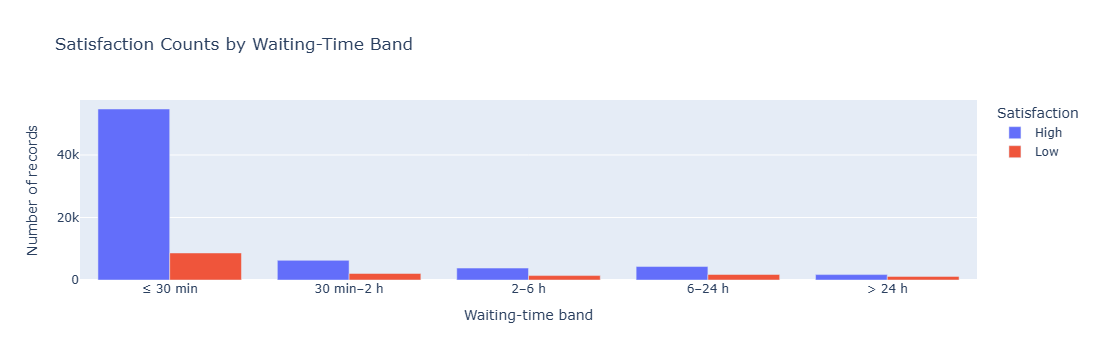

In [10]:
wait_bins = [-0.001, 0.5, 2, 6, 24, np.inf]
wait_labels = ["≤ 30 min", "30 min–2 h", "2–6 h", "6–24 h", "> 24 h"]
df["Waiting Category"] = pd.cut(
    df["waiting_time_hours"], bins=wait_bins, labels=wait_labels, include_lowest=True
)

wait_band_counts = (
    df.groupby(["Waiting Category", "Satisfaction"], observed=False)
      .size().reset_index(name="Customers")
)
fig = px.bar(
    wait_band_counts, x="Waiting Category", y="Customers", color="Satisfaction",
    barmode="group", title="Satisfaction Counts by Waiting-Time Band"
)
fig.update_layout(xaxis_title="Waiting-time band", yaxis_title="Number of records")
fig.show()


## Cell 10 — Service category vs satisfaction
This chart compares the high-satisfaction percentage by service/issue category. Rates should be interpreted with group sizes in mind.

,category,Records,High_Satisfaction_Rate
6,Others,99,59.60
1,Cancellation,2212,75.90
8,Product Queries,3692,76.90
5,Order Related,23215,78.56
2,Feedback,2294,79.86
4,Onboarding related,65,81.54
9,Refund Related,4550,82.33
3,Offers & Cashback,480,82.92
11,Shopzilla Related,2792,83.99
10,Returns,44097,85.24


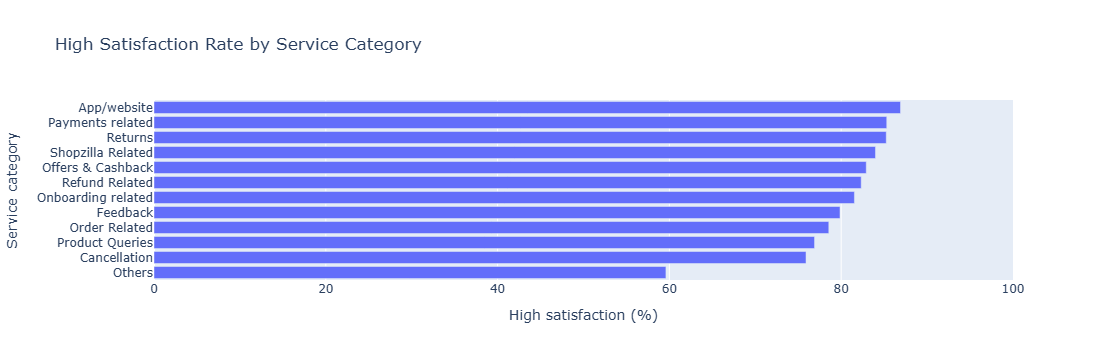

In [11]:
category_summary = df.groupby("category", dropna=False).agg(
    Records=("Satisfaction", "size"),
    High_Satisfaction_Rate=("Satisfaction", lambda s: (s == "High").mean() * 100)
).reset_index().sort_values("High_Satisfaction_Rate")

category_summary["category"] = category_summary["category"].fillna("Unknown").astype(str)
display(category_summary.round(2))

fig = px.bar(
    category_summary, x="High_Satisfaction_Rate", y="category", orientation="h",
    hover_data=["Records"], title="High Satisfaction Rate by Service Category",
    labels={"High_Satisfaction_Rate":"High satisfaction (%)", "category":"Service category"}
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()


## Cell 11 — Product category vs satisfaction
Identify product categories with comparatively lower high-satisfaction rates.

,Product_category,Records,High_Satisfaction_Rate
4,GiftCard,26,57.69
3,Furniture,471,66.03
8,Mobile,1758,66.55
6,Home Appliences,1300,68.31
5,Home,1328,75.15
2,Electronics,4706,76.54
1,Books & General merchandise,3323,76.74
7,LifeStyle,4118,79.16
0,Affiliates,166,82.53
9,Unknown,68711,84.27


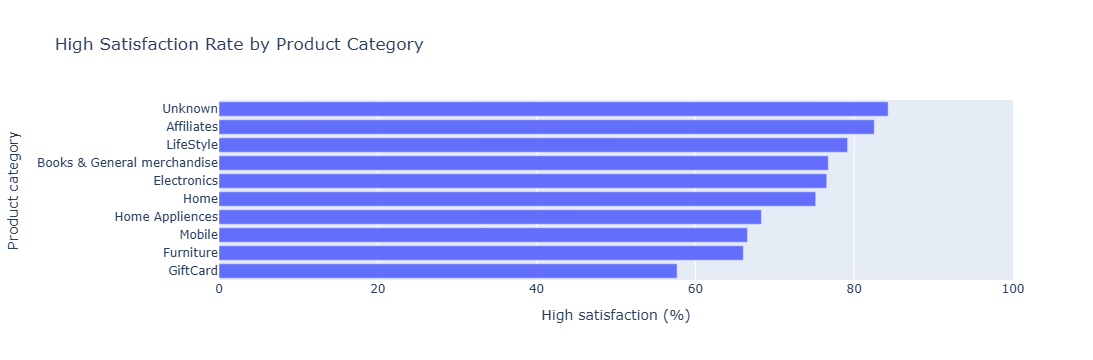

In [12]:
product_summary = df.groupby("Product_category", dropna=False).agg(
    Records=("Satisfaction", "size"),
    High_Satisfaction_Rate=("Satisfaction", lambda s: (s == "High").mean() * 100)
).reset_index().sort_values("High_Satisfaction_Rate")

product_summary["Product_category"] = product_summary["Product_category"].fillna("Unknown").astype(str)
display(product_summary.round(2))

fig = px.bar(
    product_summary, x="High_Satisfaction_Rate", y="Product_category", orientation="h",
    hover_data=["Records"], title="High Satisfaction Rate by Product Category",
    labels={"High_Satisfaction_Rate":"High satisfaction (%)", "Product_category":"Product category"}
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()


## Cell 12 — Agent shift vs satisfaction
Use this comparison to explore whether reported satisfaction differs across support shifts.

,Agent Shift,Records,High_Satisfaction_Rate
4,Split,3648,87.14
0,Afternoon,5840,83.77
1,Evening,33677,83.34
3,Night,1316,82.83
2,Morning,41426,81.13


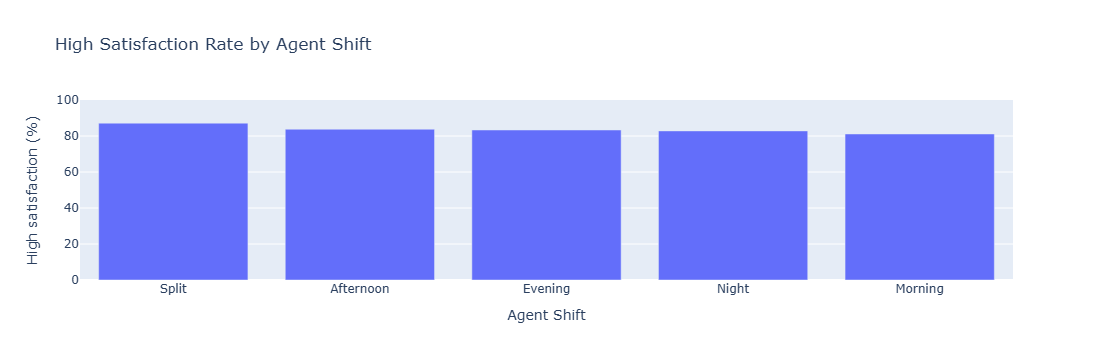

In [13]:
shift_summary = df.groupby("Agent Shift", dropna=False).agg(
    Records=("Satisfaction", "size"),
    High_Satisfaction_Rate=("Satisfaction", lambda s: (s == "High").mean() * 100)
).reset_index().sort_values("High_Satisfaction_Rate", ascending=False)

shift_summary["Agent Shift"] = shift_summary["Agent Shift"].fillna("Unknown").astype(str)
display(shift_summary.round(2))

fig = px.bar(
    shift_summary, x="Agent Shift", y="High_Satisfaction_Rate",
    hover_data=["Records"], title="High Satisfaction Rate by Agent Shift",
    labels={"High_Satisfaction_Rate":"High satisfaction (%)"}
)
fig.update_layout(yaxis_range=[0, 100])
fig.show()


## Cell 13 — Issue sub-categories with low satisfaction rates
Only show issue groups with at least 30 records to avoid over-interpreting very small groups. Adjust the threshold if needed.

,Sub-category,Records,High_Satisfaction_Rate
6,Call disconnected,40,55.00
44,Service Center - Service Denial,58,60.34
5,Call back request,46,60.87
49,Technician Visit,378,64.02
42,Seller Cancelled Order,1059,65.44
54,Warranty related,78,69.23
0,Account updation,150,70.00
56,e-Gift Voucher,42,71.43
15,Installation/demo,4116,72.33
4,COD Refund Details,85,74.12


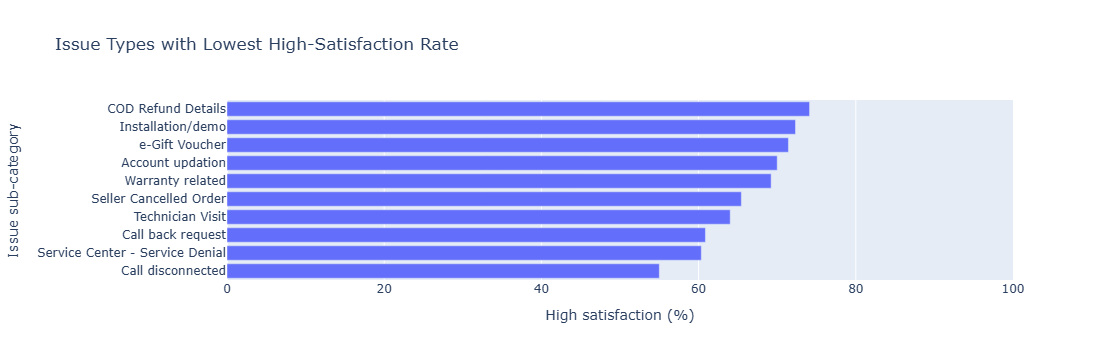

In [14]:
issue_summary = df.groupby("Sub-category", dropna=False).agg(
    Records=("Satisfaction", "size"),
    High_Satisfaction_Rate=("Satisfaction", lambda s: (s == "High").mean() * 100)
).reset_index()
issue_summary = issue_summary[issue_summary["Records"] >= 30].sort_values("High_Satisfaction_Rate").head(10)
issue_summary["Sub-category"] = issue_summary["Sub-category"].fillna("Unknown").astype(str)
display(issue_summary.round(2))

fig = px.bar(
    issue_summary, x="High_Satisfaction_Rate", y="Sub-category", orientation="h",
    hover_data=["Records"], title="Issue Types with Lowest High-Satisfaction Rate",
    labels={"High_Satisfaction_Rate":"High satisfaction (%)", "Sub-category":"Issue sub-category"}
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()


## Cell 14 — Train a Decision Tree without target leakage
The original `CSAT Score` and derived `Satisfaction` are not predictors. The model uses waiting time and service-related categorical features. A pipeline handles missing values and one-hot encodes categories.

In [15]:
feature_columns = [
    "waiting_time_hours", "category", "Sub-category",
    "Product_category", "Agent Shift", "channel_name"
]
target = (df["Satisfaction"] == "High").astype(int)
X = df[feature_columns].copy()

numeric_features = ["waiting_time_hours"]
categorical_features = [c for c in feature_columns if c not in numeric_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8, random_state=42, class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.20, random_state=42, stratify=target
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")
print("Model training complete.")


Training records: 68,725
Testing records: 17,182
Model training complete.


## Cell 15 — Model metrics
Accuracy alone is not enough. Recall for the low-satisfaction class is especially important. In this model, class 0 = Low and class 1 = High, so we calculate low-class recall separately.

,Metric,Score
0,Accuracy,0.6673
1,Precision (High),0.8897
2,Recall (High),0.6809
3,F1-score (High),0.7714
4,Precision (Low),0.2868
5,Recall (Low),0.6032
6,F1-score (Low),0.3888
7,ROC-AUC,0.6786


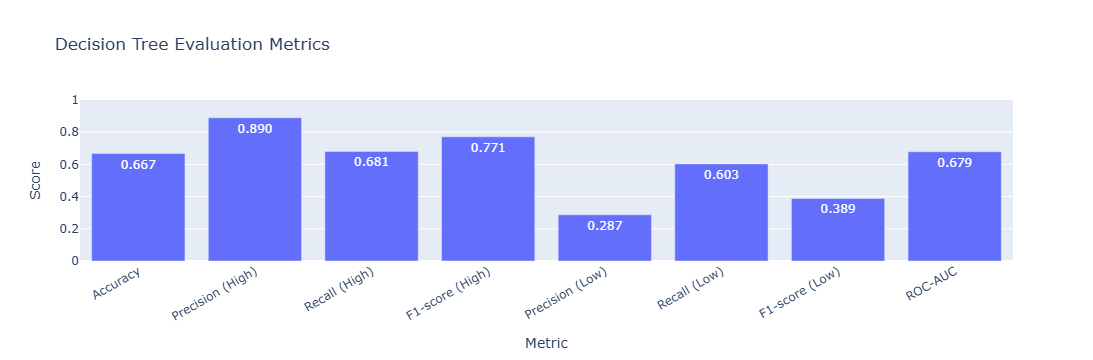

              precision    recall  f1-score   support

         Low       0.29      0.60      0.39      3014
        High       0.89      0.68      0.77     14168

    accuracy                           0.67     17182
   macro avg       0.59      0.64      0.58     17182
weighted avg       0.78      0.67      0.70     17182



In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision_high = precision_score(y_test, y_pred, zero_division=0)
recall_high = recall_score(y_test, y_pred, zero_division=0)
f1_high = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

low_recall = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
low_precision = precision_score(y_test, y_pred, pos_label=0, zero_division=0)
low_f1 = f1_score(y_test, y_pred, pos_label=0, zero_division=0)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (High)", "Recall (High)", "F1-score (High)",
               "Precision (Low)", "Recall (Low)", "F1-score (Low)", "ROC-AUC"],
    "Score": [accuracy, precision_high, recall_high, f1_high,
              low_precision, low_recall, low_f1, roc_auc]
})
display(metrics.round(4))

fig = px.bar(metrics, x="Metric", y="Score", title="Decision Tree Evaluation Metrics", text_auto=".3f")
fig.update_layout(yaxis_range=[0, 1], xaxis_tickangle=-30)
fig.show()

print(classification_report(y_test, y_pred, target_names=["Low", "High"], zero_division=0))


## Cell 16 — Confusion matrix
The confusion matrix shows correct and incorrect predictions for each satisfaction class.

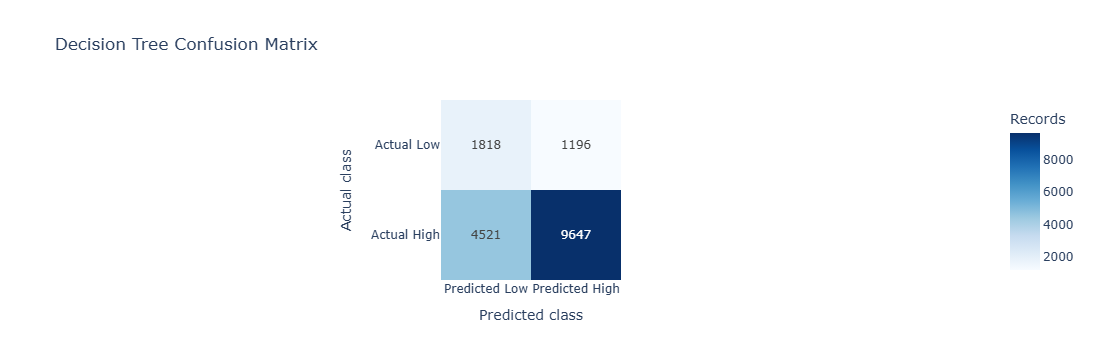

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig = px.imshow(
    cm, text_auto=True, x=["Predicted Low", "Predicted High"],
    y=["Actual Low", "Actual High"], color_continuous_scale="Blues",
    title="Decision Tree Confusion Matrix",
    labels={"x":"Predicted class", "y":"Actual class", "color":"Records"}
)
fig.show()


## Cell 17 — Feature importance
Feature importance is extracted from the trained tree after one-hot encoding. These values describe predictive contribution, not proof of causation.

,Feature,Importance
0,numeric__waiting_time_hours,0.6066
52,categorical__Sub-category_Return request,0.1271
26,categorical__Sub-category_Fraudulent User,0.0749
33,categorical__Sub-category_Missing,0.0397
68,categorical__Sub-category_Wrong,0.0357
72,categorical__Product_category_Electronics,0.0351
28,categorical__Sub-category_Installation/demo,0.0138
84,categorical__channel_name_Email,0.0102
81,categorical__Agent Shift_Morning,0.0092
77,categorical__Product_category_LifeStyle,0.0075


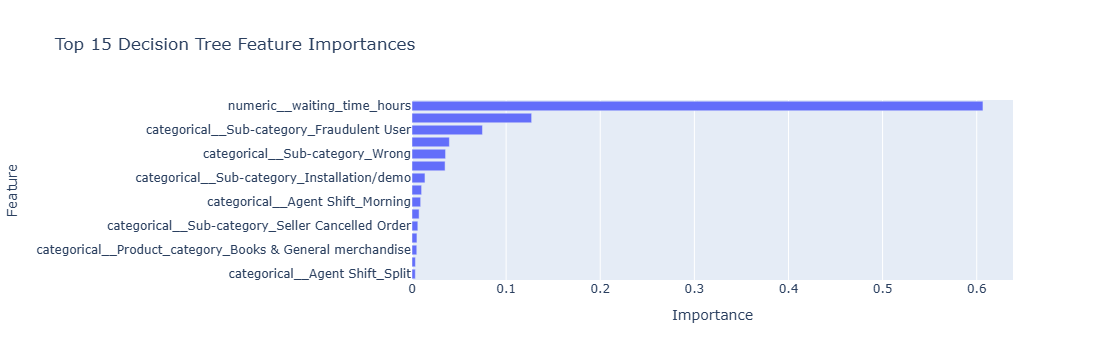

In [18]:
preprocessor_fitted = model.named_steps["preprocessor"]
tree = model.named_steps["classifier"]
feature_names = preprocessor_fitted.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(15).round(4))

fig = px.bar(
    importance.head(15).sort_values("Importance"),
    x="Importance", y="Feature", orientation="h",
    title="Top 15 Decision Tree Feature Importances"
)
fig.show()


## Cell 18 — Optional interactive filters
If `ipywidgets` is installed, choose service category and agent shift to explore a filtered satisfaction summary. If widgets do not render in your Jupyter environment, use the Plotly charts above or install/enable ipywidgets.

In [19]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    category_options = ["All"] + sorted(df["category"].dropna().astype(str).unique().tolist())
    shift_options = ["All"] + sorted(df["Agent Shift"].dropna().astype(str).unique().tolist())

    category_dropdown = widgets.Dropdown(options=category_options, description="Category:")
    shift_dropdown = widgets.Dropdown(options=shift_options, description="Agent shift:")
    output = widgets.Output()

    def update_filtered_view(*args):
        with output:
            clear_output(wait=True)
            view = df.copy()
            if category_dropdown.value != "All":
                view = view[view["category"].astype(str) == category_dropdown.value]
            if shift_dropdown.value != "All":
                view = view[view["Agent Shift"].astype(str) == shift_dropdown.value]

            if view.empty:
                print("No records match these filters.")
                return

            summary = view["Satisfaction"].value_counts().rename_axis("Satisfaction").reset_index(name="Records")
            display(summary)
            print(f"Records: {len(view):,}")
            print(f"High satisfaction: {(view['Satisfaction'] == 'High').mean()*100:.2f}%")
            print(f"Mean waiting time: {view['waiting_time_hours'].mean():.2f} hours")

    category_dropdown.observe(update_filtered_view, names="value")
    shift_dropdown.observe(update_filtered_view, names="value")
    display(widgets.HBox([category_dropdown, shift_dropdown]), output)
    update_filtered_view()
except ImportError:
    print("ipywidgets is not installed. Run: %pip install ipywidgets")


Output()

## Cell 19 — Export summary tables
Save key EDA tables and metrics so they can be added to the written report if needed.

In [20]:
category_summary.to_csv("satisfaction_by_service_category.csv", index=False)
product_summary.to_csv("satisfaction_by_product_category.csv", index=False)
shift_summary.to_csv("satisfaction_by_agent_shift.csv", index=False)
metrics.to_csv("decision_tree_metrics.csv", index=False)

print("Saved EDA summary tables and model metrics to the current folder.")


Saved EDA summary tables and model metrics to the current folder.


## Cell 20 — Dashboard conclusions template
Use the actual output from the cells above to write conclusions. Avoid claiming that a factor causes dissatisfaction; these charts show associations.

Suggested points to discuss:
- Overall proportion of high and low satisfaction.
- Whether median/mean waiting time differs between satisfaction groups.
- Service and product categories with lower high-satisfaction rates, considering their record counts.
- Agent shifts with different satisfaction patterns.
- Accuracy, precision, recall, F1-score, ROC-AUC, and especially recall for Low satisfaction.
- Top encoded features from the feature-importance chart.
- Recommendations: response-time alerts, targeted follow-up, investigation of low-performing issue types, and continued model monitoring.
